In [ ]:
!pip install pandas numpy matplotlib seaborn scikit-learn

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving jiomart.csv to jiomart.csv


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("jiomart.csv")

print("Dataset Shape:", df.shape)

df.head()

Dataset Shape: (1026, 7)


,Index,product,category,sale_price,market_price,type,rating
0,1,Pro Garlic Oil - Vegetarian Capsule 500 mg Model,Beauty & Hygiene,220.00,220.00,Hair Oil & Serum,4.1
1,2,Fusion Water Bottle - Orange Premium Pack,"Kitchen, Garden & Pets",180.00,180.00,Water & Fridge Bottles,2.3
2,3,Amul Butter 100g (Carton),Groceries,58.00,60.00,Dairy & Bakery,3.6
3,4,Amul Butter 500g (Carton),Groceries,285.00,295.00,Dairy & Bakery,3.6
4,5,"Essential Brass Angle Deep - Plain, No.2 Set",Cleaning & Household,119.00,250.00,Lamp & Lamp Oil,3.4


In [ ]:
# Dataset information
df.info()

# Check missing values
print(df.isnull().sum())

# Statistical information
df.describe()

# Check duplicate records
print("Duplicates:", df.duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1026 entries, 0 to 1025
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Index         1026 non-null   int64  
 1   product       1026 non-null   object 
 2   category      1026 non-null   object 
 3   sale_price    1026 non-null   object 
 4   market_price  1026 non-null   object 
 5   type          1026 non-null   object 
 6   rating        1026 non-null   float64
dtypes: float64(1), int64(1), object(5)
memory usage: 56.2+ KB
Index           0
product         0
category        0
sale_price      0
market_price    0
type            0
rating          0
dtype: int64
Duplicates: 0


In [ ]:
df.columns = df.columns.str.strip().str.lower()

df["sale_price"] = pd.to_numeric(
    df["sale_price"].astype(str).str.replace(",", ""),
    errors="coerce"
)

df["market_price"] = pd.to_numeric(
    df["market_price"].astype(str).str.replace(",", ""),
    errors="coerce"
)

df["rating"] = pd.to_numeric(df["rating"], errors="coerce")

print(df.head())

   index                                           product  \
0      1  Pro Garlic Oil - Vegetarian Capsule 500 mg Model   
1      2         Fusion Water Bottle - Orange Premium Pack   
2      3                         Amul Butter 100g (Carton)   
3      4                         Amul Butter 500g (Carton)   
4      5      Essential Brass Angle Deep - Plain, No.2 Set   

                 category  sale_price  market_price                    type  \
0        Beauty & Hygiene       220.0         220.0        Hair Oil & Serum   
1  Kitchen, Garden & Pets       180.0         180.0  Water & Fridge Bottles   
2               Groceries        58.0          60.0          Dairy & Bakery   
3               Groceries       285.0         295.0          Dairy & Bakery   
4    Cleaning & Household       119.0         250.0         Lamp & Lamp Oil   

   rating  
0     4.1  
1     2.3  
2     3.6  
3     3.6  
4     3.4  


In [ ]:
df["discount"] = df["market_price"] - df["sale_price"]

df["discount_percentage"] = (
    df["discount"] / df["market_price"]
) * 100

df[["product", "sale_price", "market_price",
    "discount_percentage"]].head(10)

,product,sale_price,market_price,discount_percentage
0,Pro Garlic Oil - Vegetarian Capsule 500 mg Model,220.0,220.0,0.000000
1,Fusion Water Bottle - Orange Premium Pack,180.0,180.0,0.000000
2,Amul Butter 100g (Carton),58.0,60.0,3.333333
3,Amul Butter 500g (Carton),285.0,295.0,3.389831
4,"Essential Brass Angle Deep - Plain, No.2 Set",119.0,250.0,52.400000
5,Signature Cereal Flip Lid Container/Storage Ja...,149.0,176.0,15.340909
6,Essential Creme Soft Soap - For Hands & Body B...,162.0,162.0,0.000000
7,Fusion Germ - Removal Multipurpose Wipes Range,169.0,199.0,15.075377
8,VLITE Food Wrapping Butter Paper Roll- (Medium...,139.0,430.0,67.674419
9,Signature Multani Mati Edition,58.0,58.0,0.000000


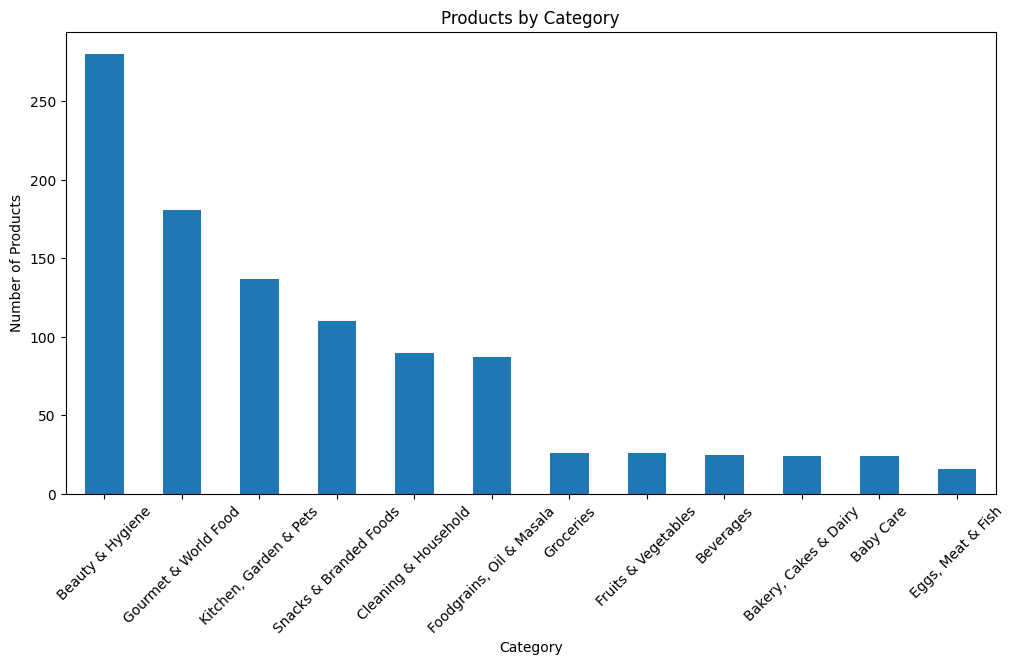

In [ ]:
plt.figure(figsize=(12,6))

df["category"].value_counts().plot(kind="bar")

plt.title("Products by Category")
plt.xlabel("Category")
plt.ylabel("Number of Products")

plt.xticks(rotation=45)
plt.show()

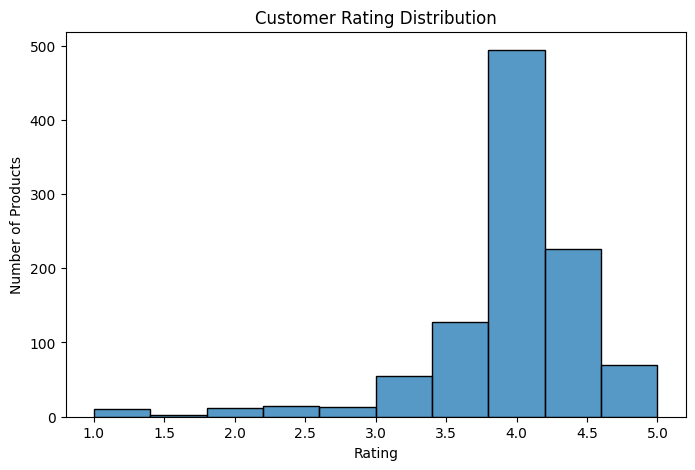

In [ ]:
plt.figure(figsize=(8,5))

sns.histplot(df["rating"].dropna(), bins=10)

plt.title("Customer Rating Distribution")
plt.xlabel("Rating")
plt.ylabel("Number of Products")

plt.show()